# Getting started

Welcome to the Getting Started guide of `l2co`! This document will help you set up your optimization tasks, optimizers and get familiar with the basics.

## Table of Contents

- [Task class](#task-class)
- [Optimizer class](#optimizer-class)
- [Budget function](#budget-function)
- [Samplers](#samplers)
- [Running optimization](#running-optimization)
- [Analyzing results](#analyzing-results)

## Task class

The [`Task`](api.md/#l2co.Task) class is one of the core components of `l2co`, representing the optimization problem you want to solve. It encapsulates the following elements:

- **objective Function** (`loss_fn`): The function you want to minimize. Currently, only single-objective and minimization tasks are supported. The function should take a single PyTree (`eqx.Module` or nested structures of arrays) as the first positional input and return a scalar loss value.
- **model** (`model`): The model or parameters that you want to optimize. This is typically an instance of `eqx.Module` or a nested structure of arrays.
- **global_min** (`global_min`): The known global minimum value of the objective function, if available. This is used for computing performance metrics such as the Expected Running Time (ERT). Set to `None` if unknown.
- **data** (`dataset`): Optional data that may be required by the objective function. This is presented as a dictionary with three keys:
    - **dataset_path**: path to the dataset. The dataset will be lazily-loaded when the `loaded_dataset` property is accessed. The data needs to be in a dictionary format with each key represting the name of a data field and the value being jax array with the leading dimension representing the number of samples.
    - **batch_size**: size of the batches to be used during training. If `None`, the entire dataset will be used as a single batch.
    - **seed**: random seed for shuffling the dataset before creating batches.
- **has_aux**: A boolean flag indicating whether the objective function returns auxiliary information along with the loss value. If `True`, the objective function should return a tuple where the first element is the loss and the second element is a dictionary of auxiliary information.
- **tag**: An optional dictionary with string keys that can be used to identify the task.
- **pass_rng**: _(deprecated)_ A boolean flag indicating whether to pass a random number generator (RNG) to the objective function. This can be used to mimic aleatoric uncertainty in loss function.


In [1]:
from l2co import Task

The `l2co` package contains several built-in tasks for optimization problems, which can be found in the `l2co.tasks` module. You can also create custom tasks by instantiating the `Task` class and providing your own objective functions and dataset:

In [2]:
from l2co.tasks import create_bbob_task


rastrigin_function = create_bbob_task(fn_name='rastrigin', seed=42, dimensionality=10)
sphere_function = create_bbob_task(fn_name='sphere', seed=42, dimensionality=10)

rastrigin_function

Task(tag={'separable': False, 'unimodal': False, 'dimensionality': 10, 'fn_name': 'rastrigin', 'seed': 42, 'noise': 0.0})

The following built-in tasks are available in `l2co.tasks`:

- benchmark function tasks using the BBOB suite from `bbob_jax`
- cifar10 image classification task
- classification of random gaussians
- mnist1d image classification task
- PDE-based tasks (reaction, convection, diffusion)
- fitting of quadratic functions
- training a RNN for spirals classification

The `tag` parameter is useful for training the `l2co` model, as it is used as input to the classification model. Tasks with similar tags are considered to have similar loss landscapes, and are threated as different realizations of the same task.

The `Task` object can be saved to a JSON file ([`Task.save`](api.md/#l2co.Task.save)) and loaded again ([`Task.load`](api.md/#l2co.Task.load)) for later use.

## Optimizer class

The [`OptimizationStep`](api.md/#l2co.OptimizationStep) class represents the optimization algorithm used to minimize the objective function defined in a `Task` in a human-friendly way. It is used to abstract the different third-party packages that are used to implement the optimizers. It encapsulates the following elements:

- **optimizer** (`optimizer`): A string argument specifying the optimization algorithm to be used. The string argument is mapped to a registry of known optimizers ([`optimizer_mapping`](api.md/#l2co.optimizer_mapping)).
- **stopping_criteria** (`stopping_criteria`): A string argument specifying the stopping criteria for the optimization process. The string argument is mapped to a registry of known stopping criteria.
- **hyperparameters** (`hyperparameters`): A dictionary containing hyperparameters specific to the chosen optimizer. The hyperparameters are passed to the instantiation of the optimizer.

Currently, `l2co` supports the following JAX-based libraries: 

- [`optax`](https://github.com/google-deepmind/optax) for gradient-based optimization
- [`evosax`](https://github.com/RobertTLange/evosax) for gradient-free optimization. 

Although all the available optimizers from these libraries can be used, `l2co` provides a registry of commonly used optimizers that can be referenced by their string names.

Based on the given information, the [`OptimizationStep`](api.md/#l2co.OptimizationStep) class generated a `tag` attribute that identifies the optimizer and its configuration similarly to the [`Task`](api.md/#l2co.Task) class.

In [3]:
from l2co import OptimizationStep

adam_step = OptimizationStep(
    optimizer='adam',
    stopping_criteria={'type': 'gradient_based', 'grad_tol': 1e-8},
    hyperparameters={'learning_rate': 1e-3}
)

sepcmaes_step = OptimizationStep(
    optimizer='sepcmaes',
    stopping_criteria={'type': 'covariance_matrix', 'tol': 1e-12},
)

adam_step

Optimizer: adam, Hyperparameters: {'learning_rate': 0.001}, Stopping criteria: {'type': 'gradient_based', 'grad_tol': 1e-08}

The `stopping_criteria` parameter allows you to define when the optimization process should stop. This criteria is evaluated every iteration. Currently, the following stopping criteria are supported:

- **`'gradient_based'`**: Stops the optimization when the norm of the gradient falls below a specified threshold.
- **`'loss_based'`**: Stops the optimization when the change in loss value between iterations falls below a specified threshold.
- **`'combined'`**: Combines the `'gradient_based'` and `'loss_based'` criteria, stopping the optimization when either condition is met.
- **`'covariance_matrix'`**: Stops the optimization when the maximum eigenvalue of the covariance matrix of the population (for evolutionary strategies) falls below a specified threshold.

The [`OptimizationStep`](api.md/#l2co.OptimizationStep) object can be saved to a JSON file ([`OptimizationStep.save`](api.md/#l2co.OptimizationStep.save)) and loaded again ([`OptimizationStep.load`](api.md/#l2co.OptimizationStep.load)) for later use.

## Budget function

In order to solve an optimization problem using `l2co`, you need to define a maximum number of iterations to specify how many update steps should be performed for a given task, assuming that the stopping criteria is not met before reaching this limit. This is done using a budget function.

Currently there are 2 budget functions available in `l2co`:

- **`fixed_budget`**: A simple budget function that always returns a fixed integer value representing the maximum number of iterations.
- **`based_on_dimensionality`**: A budget function that calculates the maximum number of iterations based on the dimensionality of the task ([`Task.dimensionality`](api.md/#l2co.Task.dimensionality)). The budget is computed as `budget_per_dimension * dimensionality`. An optional `max_iterations` parameter can be provided to cap the budget at a fixed upper limit, which is useful when working with high-dimensional tasks where the linear scaling would produce an impractically large budget.

In [4]:
from l2co.budget import based_on_dimensionality, fixed_budget

The budget function takes any arguments and returns an integer value representing the maximum number of iterations for the optimization process.

In [5]:
from functools import partial

budget_fn = partial(based_on_dimensionality, budget_per_dimension=1000)

print(f"The maximum budget is: {budget_fn(rastrigin_function)} iterations!")

# With a cap on the maximum iterations
budget_fn_capped = partial(based_on_dimensionality, budget_per_dimension=1000, max_iterations=5000)
print(f"The capped budget is: {budget_fn_capped(rastrigin_function)} iterations!")

The maximum budget is: 10000 iterations!
The capped budget is: 5000 iterations!


## Samplers

In order to initialize the parameters of the model to be optimized, `l2co` provides several samplers that can be used to generate initial values. These samplers are located in the `l2co.samplers` module and can be used to create different types of distributions for initializing the model parameters.

The following samplers are available in `l2co.samplers`:

- **[`random_sampling`](api.md/#l2co.sampling.random_sampling)**: Samples parameters uniformly at random within a specified range.
- **[`xavier_sampling`](api.md/#l2co.sampling.xavier_sampling)**: Samples parameters using Xavier initialization, which is commonly used for neural networks.
- **[`normal_sampling`](api.md/#l2co.sampling.normal_sampling)**: Samples parameters from a normal (Gaussian) distribution with specified mean and standard deviation.
- **[`grid_sampling`](api.md/#l2co.sampling.grid_sampling)**: Samples parameters on a grid within a specified range, useful for low-dimensional problems or hyperparameter sweeps.
- **[`constant_sampling`](api.md/#l2co.sampling.constant_sampling)**: Fills all parameters with a single constant value. Useful for creating baseline initial conditions.

In [6]:
from l2co.sampling import random_sampling, xavier_sampling, normal_sampling, grid_sampling, constant_sampling
import jax.random as jr
import equinox as eqx

# Partition the model parameters into inexact arrays (the parameters to be sampled) and static data
params, static = eqx.partition(rastrigin_function.model, eqx.is_inexact_array)

normal_sampling(key=jr.key(0), params=params, n_samples=5, mean=0.0, std=0.1)

Array([[ 0.10040142, -0.09063372, -0.07481723, -0.11713669, -0.08712328,
         0.05888381,  0.07239299, -0.10255982,  0.1661628 , -0.18910252],
       [-0.12889339,  0.01336069, -0.11530393,  0.02392963,  0.17448074,
         0.05050189,  0.0595053 , -0.04728381,  0.09156375,  0.03612034],
       [-0.06341644, -0.0870491 ,  0.0758388 ,  0.10628535,  0.09083565,
        -0.04923202,  0.08884921,  0.16453908, -0.2515866 ,  0.04417807],
       [ 0.18173127, -0.11731388, -0.05887164,  0.21469851,  0.08018804,
        -0.01974543, -0.17398049, -0.08214191, -0.23626772,  0.15526493],
       [ 0.1405427 ,  0.03503792,  0.00624631,  0.11470389, -0.02124552,
        -0.03396749,  0.06888535, -0.03392388,  0.04920053,  0.02115948]],      dtype=float32)

## Running optimization

Now that we have identified the components required to run an optimization using `l2co`, we can proceed to set up and execute the optimization process. This involves creating instances of the [`Task`](api.md/#l2co.Task), [`OptimizationStep`](api.md/#l2co.OptimizationStep) and defining a budget function and a sampler function. Once everything is set up, we can create an instance of the [`RolloutWrapper`](api.md/#l2co.RolloutWrapper) class to manage the optimization process:

In [7]:
from l2co import RolloutWrapper

In [8]:
rollout_wrapper = RolloutWrapper.init(
    optimizer=adam_step,
    task=rastrigin_function,
    sampler=normal_sampling,
    key=jr.key(42),
    bounded=(-5.0, 5.0), # Optional box constraints for the loss function space
    verbose=True,
)

The [`RolloutWrapper.init`](api.md/#l2co.RolloutWrapper.init) method initializes internally a [`RunState`](api.md/#l2co.RunState) object to keep track of the optimization progress and results. This object tracks the following information during the optimization:

- **[`history_state`](api.md/#l2co.HistoryState)**: An instance of the [`HistoryState`](api.md/#l2co.HistoryState) class that records the entire history of the optimization process, including the mean, minimum and standard deviation value of each population at each iteration. Note; it only records these statistics per iteration, so for population-based optimizers, it does not store the individual members of the population!
- **`opt_state`**: The internal state of the optimizer being used, which is updated at each iteration based on the optimization algorithm. This is eather an [`optax.GradientTransformation`](https://optax.readthedocs.io/en/latest/api/transformations.html#optax.GradientTransformation), [`optax.GradientTransformationExtraArgs`](https://optax.readthedocs.io/en/latest/api/transformations.html#optax.GradientTransformationExtraArgs) or an `evosax.EvoState`, depending on the optimizer being used.
- **[`batch_state`](api.md/#l2co.BatchState)**: Optional state information related to data batching, if applicable to the task being optimized. It only stores the indices of the samples being used in the current batch.
- **[`update_class`](api.md/#l2co.UpdateClass)**: An instance of the [`UpdateClass`](api.md/#l2co.UpdateClass) class that encapsulates the optimizer initialization, update step and stopping criteria being used for the optimization process.
- **`max_iterations`**: The maximum number of iterations allowed for the optimization process, as defined by the budget function.

In [9]:
rollout_wrapper.run_state

RunState(
  params=f32[1,10],
  best_params=f32[10],
  best_loss=f32[],
  opt_state=(
    ScaleByAdamState(count=i32[], mu=f32[1,10], nu=f32[1,10]), EmptyState()
  ),
  update_class=UpdateClass(
    init_fn=<function optax_fn.<locals>.init_fn>,
    step_fn=<function optax_fn.<locals>.step_fn>,
    stop_fn=Partial(
      func=<function gradient_based_stopping_criteria>,
      args=(),
      keywords={'grad_tol': 1e-08}
    ),
    popsize=1,
    hash=12800727
  )
)

The [`RolloutWrapper.batch_evaluate`](api.md/#l2co.RolloutWrapper.batch_evaluate) method is used to run the optimization process for a set number of different realizations. For each realization a different random key is used to initialize the model parameters and optimizers parameters.

In [10]:
run_state, batch_state, history_state = rollout_wrapper.batch_evaluate(key=jr.key(123), n_iterations=budget_fn(rastrigin_function), n_realizations=50)

Running for 10,001 iterations:   0%|          | 0/10001 [00:00<?, ?it/s]

This function returns the [`HistoryState`](api.md/#l2co.HistoryState) object from the [`RunState`](api.md/#l2co.RunState) that contains the recorded history of the optimization process across all realizations.

This JAX Array object can be further analyzed by converting it to an xarray object using the [`HistoryState.to_xarray_realizations`](api.md/#l2co.HistoryState.to_xarray_realizations) method. It accepts an optional `budget_steps` parameter for interpolating the history to a fixed number of budget steps, which is useful for normalizing trajectories of different lengths.

Additionally, the [`HistoryState.to_dataloader`](api.md/#l2co.HistoryState.to_dataloader) method can convert the history directly into a [`DataLoader`](api.md/#l2co.DataLoader) object for further analysis, given the corresponding `Task` and `OptimizationStep`.

In [11]:
xarr_history = history_state.to_xarray_realizations()
xarr_history

<xarray.Dataset> Size: 12MB
Dimensions:      (realization: 50, output_dim: 1, budget: 10000)
Coordinates:
  * output_dim   (output_dim) object 8B 'y'
  * realization  (realization) int64 400B 0 1 2 3 4 5 6 ... 43 44 45 46 47 48 49
Dimensions without coordinates: budget
Data variables:
    output_min   (realization, output_dim, budget) float32 2MB ...
    output_mean  (realization, output_dim, budget) float32 2MB ...
    output_std   (realization, output_dim, budget) float32 2MB ...
    update_step  (realization, output_dim, budget) int32 2MB ...
    fevals       (realization, output_dim, budget) int32 2MB ...
    iterations   (realization, output_dim, budget) int32 2MB ...

If you want to run multiple optimizers on different tasks, the [`RunOptimization`](api.md/#l2co.RunOptimization) class provides a higher-level interface to manage and execute multiple optimization runs in a structured way. It is inherited from a `f3dasm.DataGenerator` object and can be used in conjunction with `f3dasm`'s data handling capabilities.

The class accepts several additional configuration parameters: `clear_jax_cache` (whether to free JAX caches after each run, default `True`), `verbose` (enable logging output, default `False`), and `save_input_parameters` (whether to include input parameter histories in the output, default `False`).

In [12]:
from l2co import RunOptimization

data_generator = RunOptimization(sampler=normal_sampling, budget_fn=budget_fn, seed=3,
                n_realizations=3, bounded=(-5.0, 5.0))

We can create a design-of-experiments with different `Task` and `OptimizationStep` input parameters.

In [13]:
from f3dasm import ExperimentData
from f3dasm.design import Domain

domain = Domain()
domain.add_parameter(name='task', to_disk=True, store_function=Task.save, load_function=Task.load)
domain.add_parameter(name='optimizer schedule', to_disk=True, store_function=OptimizationStep.save, load_function=OptimizationStep.load)

input_data= [{'task': rastrigin_function, 'optimizer schedule': adam_step},
             {'task': rastrigin_function, 'optimizer schedule': sepcmaes_step},
             {'task': sphere_function, 'optimizer schedule': adam_step},
             {'task': sphere_function, 'optimizer schedule': sepcmaes_step},
             ]

experiment_data = ExperimentData(domain=domain, input_data=input_data)
experiment_data

jobs                      input            
                optimizer schedule        task
0  open  optimizer schedule/0.json  task/0.eqx
1  open  optimizer schedule/1.json  task/1.eqx
2  open  optimizer schedule/2.json  task/2.eqx
3  open  optimizer schedule/3.json  task/3.eqx

Calling the data generator will execute all the optimization runs and return a NetCDF dataset containing the results per combination of task and optimizer:

In [14]:
experiment_data = data_generator.call(data=experiment_data, mode='sequential')
experiment_data

jobs                      input                          output
                    optimizer schedule        task        loss history
0  finished  optimizer schedule/0.json  task/0.eqx  loss history/0.ncs
1  finished  optimizer schedule/1.json  task/1.eqx  loss history/1.ncs
2  finished  optimizer schedule/2.json  task/2.eqx  loss history/2.ncs
3  finished  optimizer schedule/3.json  task/3.eqx  loss history/3.ncs

The 'create_optimization_dataset_new' experiment allows you to easily set up and run a series of optimization experiments using different tasks and optimizers.

## Analyzing results

After running the optimization experiments, we can analyze the results. There are two approaches:

1. **Direct analysis from `HistoryState`**: Convert the history directly to a [`DataLoader`](api.md/#l2co.DataLoader) using the [`to_dataloader`](api.md/#l2co.HistoryState.to_dataloader) method.
2. **Batch analysis with `create_combined_odata`**: When using `RunOptimization` with `ExperimentData`, combine all individual NetCDF result files into a consolidated `.odata` file using [`create_combined_odata`](api.md/#l2co.create_combined_odata), then load with [`DataLoader.from_file`](api.md/#l2co.DataLoader.from_file).

The [`DataLoader`](api.md/#l2co.DataLoader) class provides methods for computing performance statistics, creating ERTD profiles, and filtering by task or optimizer.

### Converting HistoryState to DataLoader

The simplest way to analyze results from a single run is to convert the `HistoryState` directly into a `DataLoader` using the `to_dataloader` method:

In [15]:
from l2co import DataLoader

# Convert history_state from the earlier batch_evaluate call to a DataLoader
data_loader = history_state.to_dataloader(
    task=rastrigin_function,
    optimizer=adam_step,
)

data_loader

DataLoader(data=<xarray.Dataset> Size: 12MB
Dimensions:      (schedule: 1, output_dim: 1, budget: 10000, problem: 50,
                  target: 51, metric: 2)
Coordinates:
  * schedule     (schedule) object 8B 'adam_learning_rate=0.001'
  * output_dim   (output_dim) object 8B 'y'
  * target       (target) float64 408B 0.0 0.02 0.04 0.06 ... 0.94 0.96 0.98 1.0
  * metric       (metric) <U10 80B 'fevals' 'iterations'
  * problem      (problem) object 400B MultiIndex
  * realization  (problem) int64 400B 0 1 2 3 4 5 6 7 ... 43 44 45 46 47 48 49
  * taskID       (problem) object 400B '411d0b0ddfca41cf' ... '411d0b0ddfca41cf'
Dimensions without coordinates: budget
Data variables:
    output_min   (schedule, output_dim, budget, problem) float32 2MB ...
    output_mean  (schedule, output_dim, budget, problem) float32 2MB ...
    output_std   (schedule, output_dim, budget, problem) float32 2MB ...
    update_step  (schedule, output_dim, budget, problem) int32 2MB ...
    fevals       (schedule

### Plotting with ERTD profiles

The `DataLoader` can be used together with the `l2co.plotting` module to visualize optimization performance. The [`plot_ertd_profile`](api.md/#l2co.plotting.plot_ertd_profile) function shows the run-time distribution for the given data:

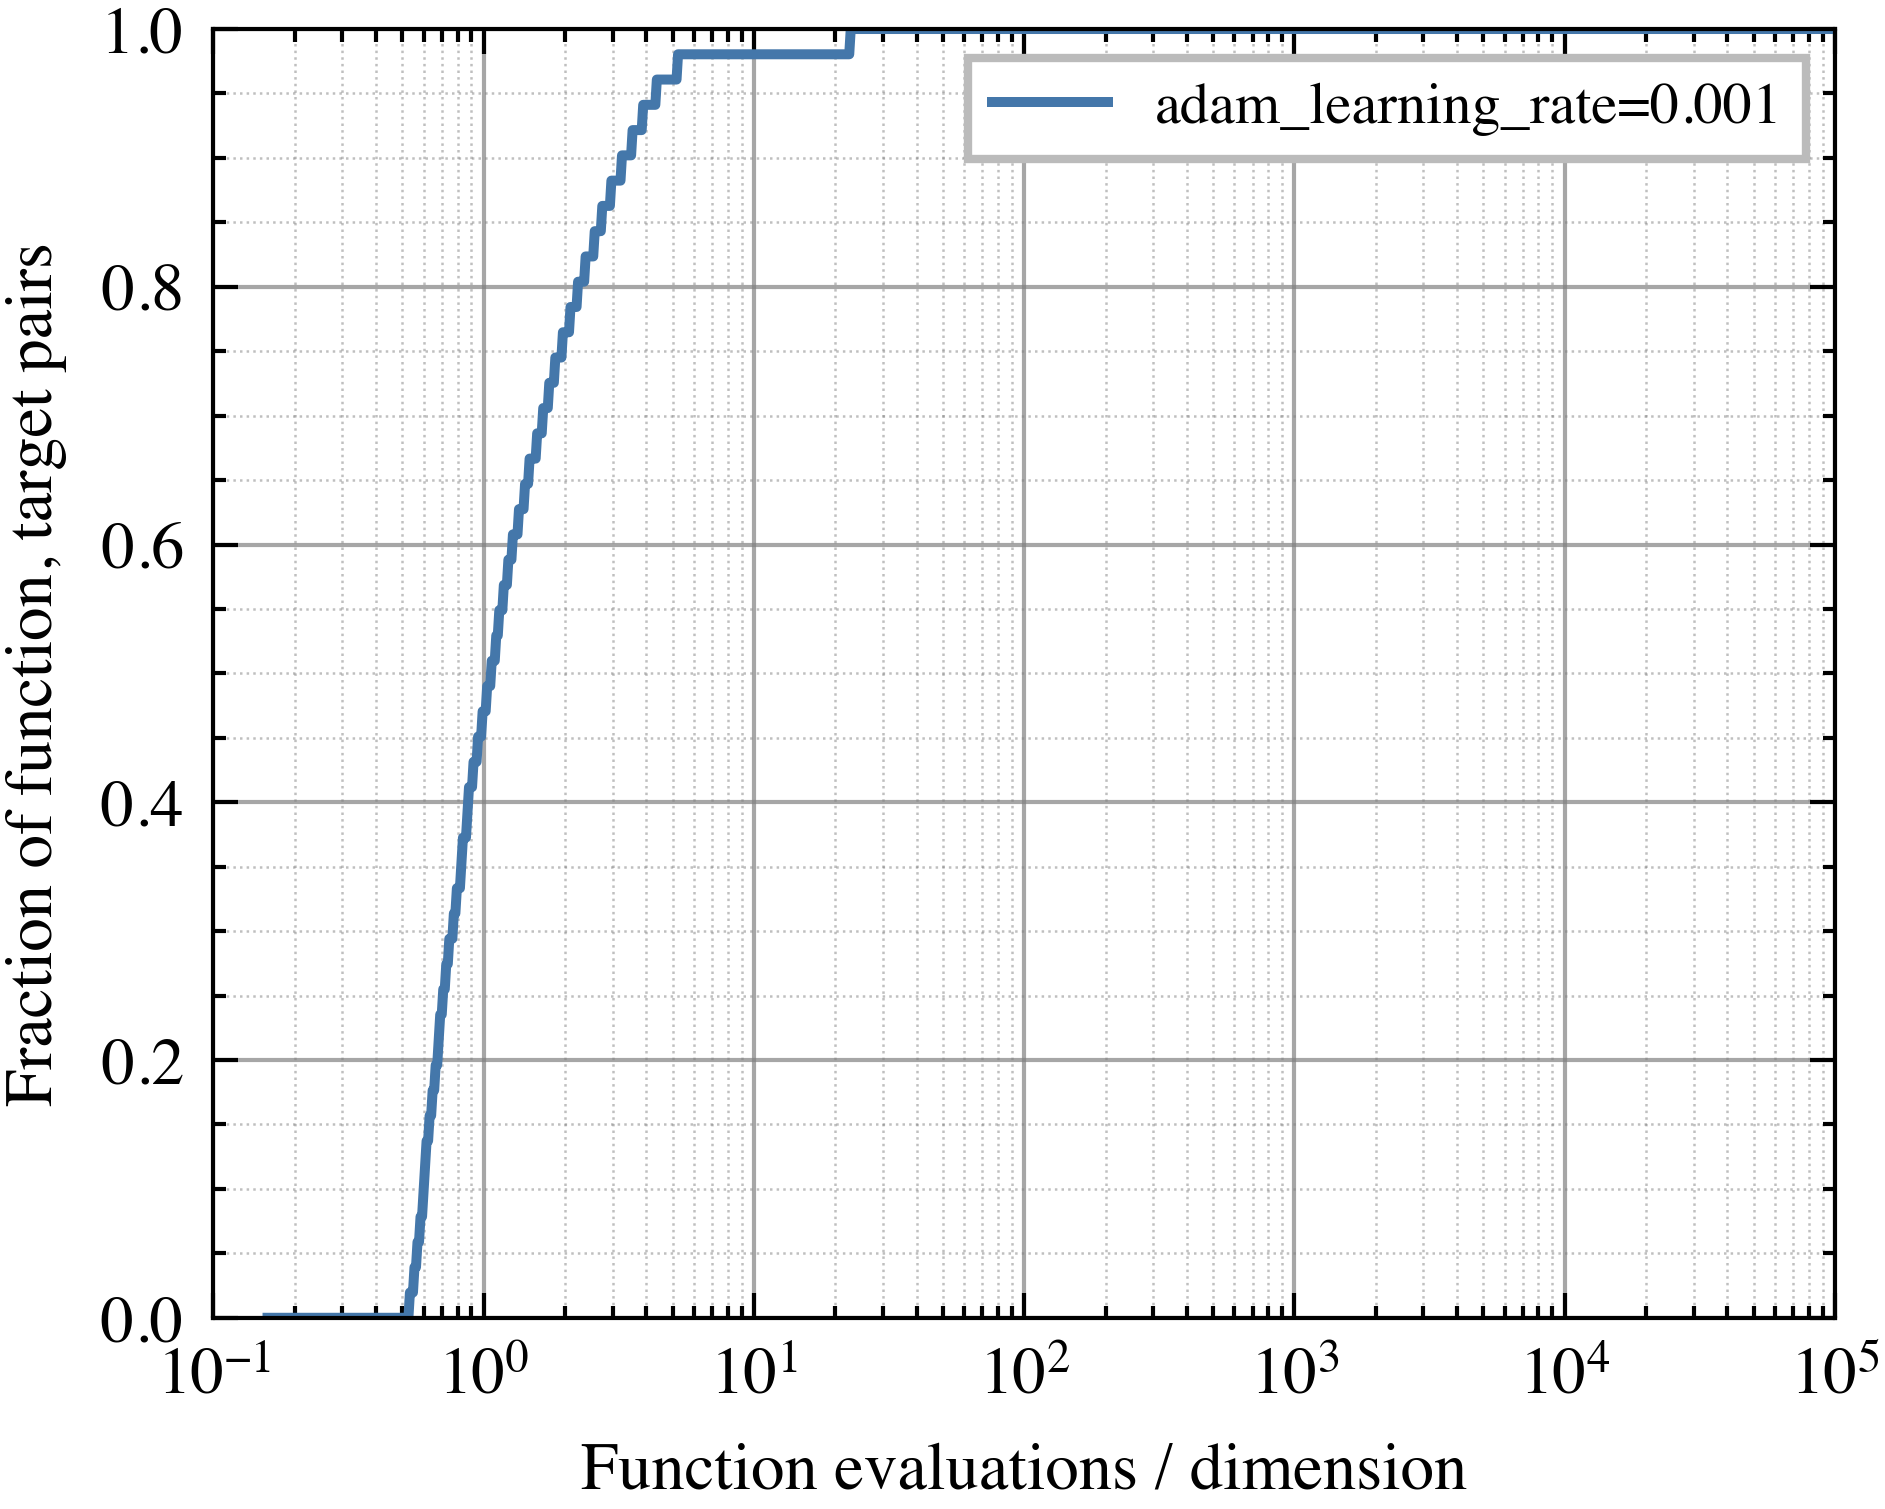

In [16]:
import l2co.plotting as plotting

fig, ax = plotting.plot_ertd_profile(data_loader)

### Inspecting the xarray data

The underlying data is stored as an `xarray.Dataset`, which you can access directly for custom analyses:

In [17]:
# Access the underlying xarray dataset
data_loader.data

<xarray.Dataset> Size: 12MB
Dimensions:      (schedule: 1, output_dim: 1, budget: 10000, problem: 50,
                  target: 51, metric: 2)
Coordinates:
  * schedule     (schedule) object 8B 'adam_learning_rate=0.001'
  * output_dim   (output_dim) object 8B 'y'
  * target       (target) float64 408B 0.0 0.02 0.04 0.06 ... 0.94 0.96 0.98 1.0
  * metric       (metric) <U10 80B 'fevals' 'iterations'
  * problem      (problem) object 400B MultiIndex
  * realization  (problem) int64 400B 0 1 2 3 4 5 6 7 ... 43 44 45 46 47 48 49
  * taskID       (problem) object 400B '411d0b0ddfca41cf' ... '411d0b0ddfca41cf'
Dimensions without coordinates: budget
Data variables:
    output_min   (schedule, output_dim, budget, problem) float32 2MB ...
    output_mean  (schedule, output_dim, budget, problem) float32 2MB ...
    output_std   (schedule, output_dim, budget, problem) float32 2MB ...
    update_step  (schedule, output_dim, budget, problem) int32 2MB ...
    fevals       (schedule, output_dim, budget, problem) int32 2MB ...
    iterations   (schedule, output_dim, budget, problem) int32 2MB ...
    cost         (schedule, metric, output_dim, target, problem) int32 20kB 2...
    success      (schedule, output_dim, target, problem) bool 3kB True ... True